                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                35078
Model:             SARIMAX(1, 0, 1)x(1, 1, 1, 24)   Log Likelihood              -59013.786
Date:                            Sat, 20 Jun 2026   AIC                         118055.572
Time:                                    03:20:14   BIC                         118174.067
Sample:                                01-01-2020   HQIC                        118093.314
                                     - 01-01-2024                                         
Covariance Type:                              opg                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
PM10                       15.8612      0.157    100.880      0.000      15.553      16.

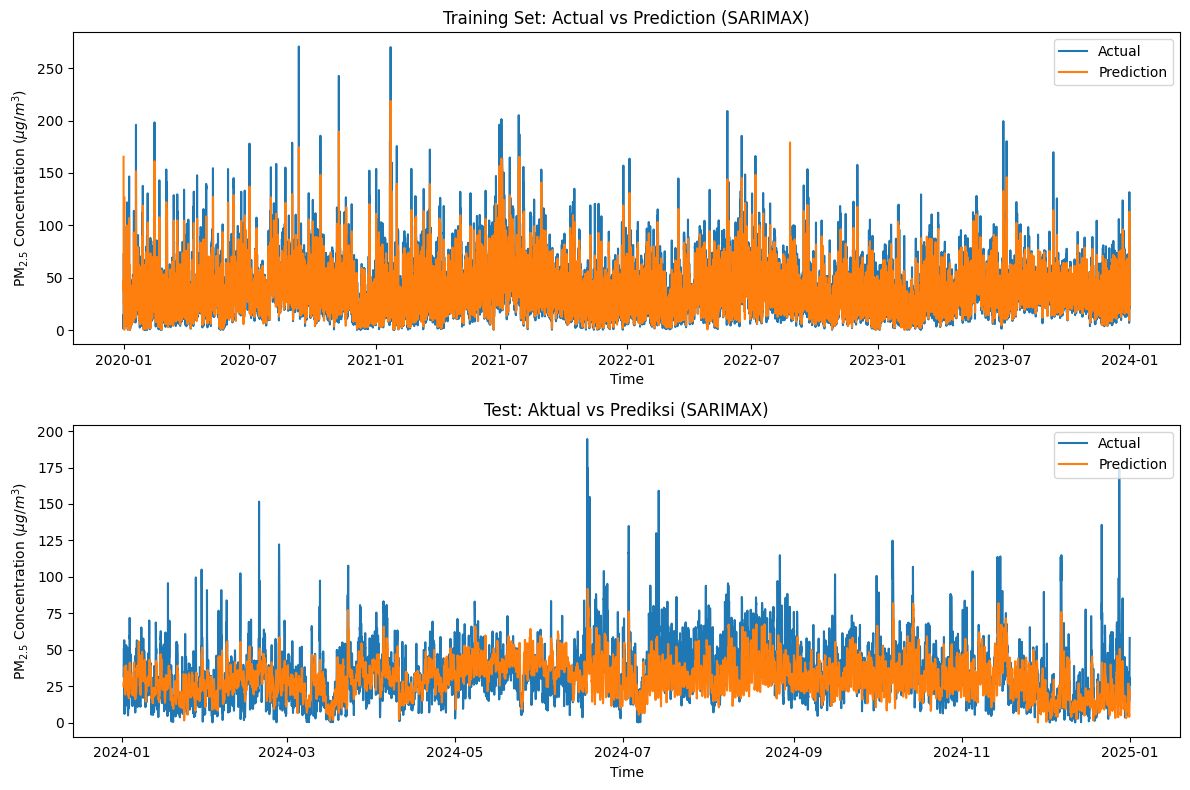

Fitting 5 folds for each of 96 candidates, totalling 480 fits

================ BEST PARAMETER ================
{'C': 20, 'epsilon': 0.0001, 'gamma': 0.01}
Best CV RMSE = 0.0558

================ HASIL EVALUASI ================

  Dataset     RMSE      MAE      R2
0   Train  14.6369  10.3107  0.5552
1    Test  16.9219  13.3975  0.1737


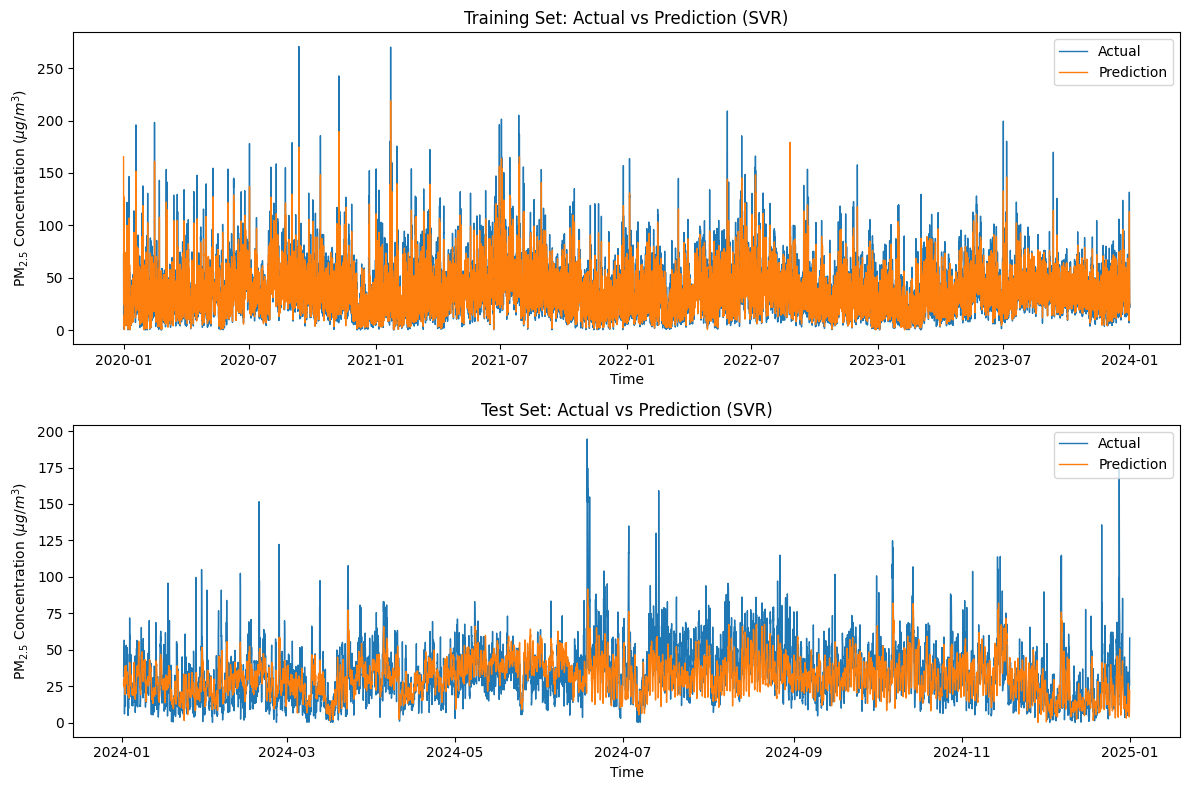


Jumlah data train : 35078
Jumlah data test  : 8770
Alpha SARIMAX = 0.90
Beta SVR      = 0.10

=== TRAIN ===
RMSE : 11.244304531754755
MAE  : 7.554352001745528
R2   : 0.7374817157244055

=== TEST ===
RMSE : 14.457965624410763
MAE  : 10.768104568734872
R2   : 0.3968248709406045


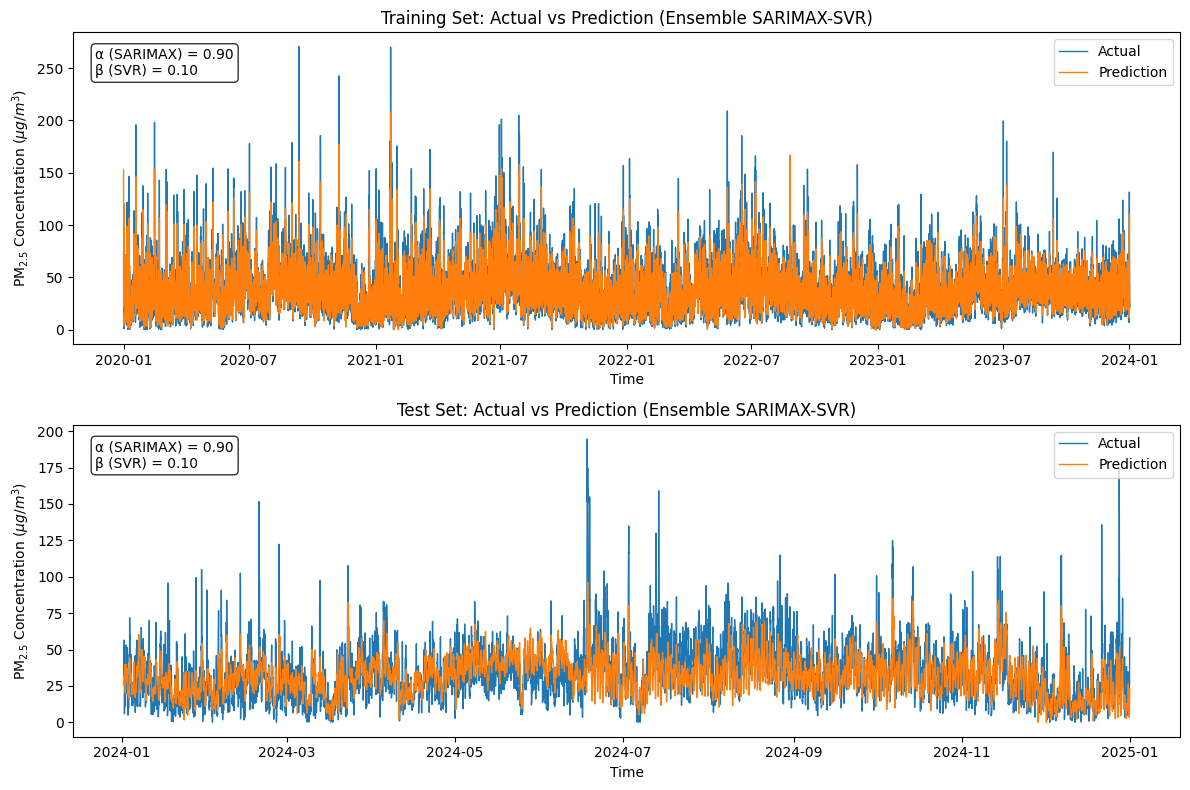

In [ ]:
# =========================
# 0. Import library
# =========================
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import PowerTransformer, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# =========================
# 1. Load data
# =========================
df_path = "/content/drive/MyDrive/Model/Data Imputasi 2/Data Final Konsentrasi Meteorologi DKI3 Jagakarsa.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

# =========================
# 2. Definisi target & eksogen
# =========================
y = df['PM2.5'].values.reshape(-1, 1)

X = df[['PM10','SO2','CO','O3','NO2',
        'Suhu Udara (°C)',
        'Kelembaban Relatif (%)',
        'Kecepatan Angin (m/s)',
        'Radiasi Matahari (W/m²)']]

# =========================
# 3. Log transform eksogen (AMAN)
# =========================
X_log = np.log1p(X)

# =========================
# 4. Train-test split
# =========================
train_size = int(len(df) * 0.8)

y_train_raw = y[:train_size]
y_test_raw  = y[train_size:]

exog_train = X_log.iloc[:train_size]
exog_test  = X_log.iloc[train_size:]

# =========================
# 5. Scaling eksogen (MinMax)
# =========================
scaler_exog = MinMaxScaler()

exog_train_scaled = pd.DataFrame(
    scaler_exog.fit_transform(exog_train),
    columns=exog_train.columns,
    index=exog_train.index
)

exog_test_scaled = pd.DataFrame(
    scaler_exog.transform(exog_test),
    columns=exog_test.columns,
    index=exog_test.index
)

# =========================
# 6. Box-Cox transform target
# =========================
if np.any(y_train_raw <= 0):
    y_shift = np.abs(np.min(y_train_raw)) + 1
else:
    y_shift = 0

y_train_pos = y_train_raw + y_shift
y_test_pos  = y_test_raw  + y_shift

pt = PowerTransformer(method='box-cox', standardize=False)

y_train = pt.fit_transform(y_train_pos)
y_test  = pt.transform(y_test_pos)

# =========================
# 7. Fit SARIMAX
# =========================
order = (1, 0, 1)
seasonal_order = (1, 1, 1, 24)

model = SARIMAX(
    y_train.flatten(),
    exog=exog_train_scaled,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit(disp=False)

print(result.summary())

# =========================
# 8. Prediksi
# =========================
pred_train = result.predict(
    start=0,
    end=len(y_train)-1,
    exog=exog_train_scaled
)

pred_test = result.predict(
    start=len(y_train),
    end=len(y_train)+len(y_test)-1,
    exog=exog_test_scaled
)

# =========================
# 9. Inverse Box-Cox
# =========================
pred_train_inv = pt.inverse_transform(
    pred_train.to_numpy().reshape(-1, 1)
).flatten() - y_shift

pred_test_inv = pt.inverse_transform(
    pred_test.to_numpy().reshape(-1, 1)
).flatten() - y_shift

y_train_inv = pt.inverse_transform(y_train).flatten() - y_shift
y_test_inv  = pt.inverse_transform(y_test).flatten() - y_shift

# =========================
# 10. Evaluasi
# =========================
def print_metrics(true, pred, label=""):
    mask = ~np.isnan(true) & ~np.isnan(pred)
    true_clean = true[mask]
    pred_clean = pred[mask]

    print(f"\n=== {label} ===")
    print("MAE :", mean_absolute_error(true_clean, pred_clean))
    print("RMSE:", np.sqrt(mean_squared_error(true_clean, pred_clean)))
    print("R2  :", r2_score(true_clean, pred_clean))

print_metrics(y_train_inv, pred_train_inv, "Train")
print_metrics(y_test_inv, pred_test_inv, "Test")

# =========================
# 11. Plot hasil
# =========================
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

ax[0].plot(df.index[:train_size], y_train_inv, label='Actual')
ax[0].plot(df.index[:train_size], pred_train_inv, label='Prediction')
ax[0].set_title('Training Set: Actual vs Prediction (SARIMAX)')
ax[0].set_ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
ax[0].set_xlabel('Time')
ax[0].legend(loc='upper right')

ax[1].plot(df.index[train_size:], y_test_inv, label='Actual')
ax[1].plot(df.index[train_size:], pred_test_inv, label='Prediction')
ax[1].set_title('Test: Aktual vs Prediksi (SARIMAX)')
ax[1].legend()
ax[1].set_ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
ax[1].set_xlabel('Time')
ax[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

# =====================================================
# SIMPAN HASIL SARIMAX SEBELUM MASUK KE BLOK SVR
# =====================================================

sarimax_train_pred = pred_train_inv.copy()
sarimax_test_pred  = pred_test_inv.copy()

y_train_actual = y_train_raw.flatten()
y_test_actual  = y_test_raw.flatten()

# ===============================
# IMPORT LIBRARY
# ===============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ===============================
# LOAD DATA
# ===============================
df_path = "/content/drive/MyDrive/Model/Data Imputasi 2/Data Final Konsentrasi Meteorologi DKI3 Jagakarsa.xlsx"

df = pd.read_excel(
    df_path,
    parse_dates=['datetime'],
    index_col='datetime'
)

# Target
y = df['PM2.5']

# Variabel input
X = df[['PM10',
        'SO2',
        'CO',
        'O3',
        'NO2',
        'Suhu Udara (°C)',
        'Kelembaban Relatif (%)',
        'Kecepatan Angin (m/s)',
        'Radiasi Matahari (W/m²)']]
# ===============================
# LOG TRANSFORM SEMUA EKSOGEN
# ===============================

X = np.log1p(X)

# ===============================
# TRAIN TEST SPLIT (80:20)
# ===============================

train_size = int(len(df) * 0.8)

X_train = X.iloc[:train_size]
X_test  = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test  = y.iloc[train_size:]

# ===============================
# SCALING
# ===============================

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled  = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(
    y_train.values.reshape(-1,1)
).ravel()

y_test_scaled = scaler_y.transform(
    y_test.values.reshape(-1,1)
).ravel()

# ===============================
# HYPERPARAMETER TUNING
# ===============================
tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'C': [10, 12, 14, 16, 18, 20],
    'gamma': [0.001, 0.004, 0.007, 0.01],
    'epsilon': [0.0001, 0.0004, 0.0007, 0.001]
}

grid = GridSearchCV(
    estimator=SVR(kernel='rbf'),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=2
)

grid.fit(
    X_train_scaled,
    y_train_scaled
)

# ===============================
# PARAMETER TERBAIK
# ===============================
print("\n================ BEST PARAMETER ================")
print(grid.best_params_)
print(f"Best CV RMSE = {-grid.best_score_:.4f}")

svr = grid.best_estimator_

# ===============================
# PREDIKSI SVR
# ===============================
pred_train_scaled = svr.predict(X_train_scaled)

pred_test_scaled = svr.predict(X_test_scaled)

# ===============================
# INVERSE SCALER
# ===============================
svr_train_pred = scaler_y.inverse_transform(
    pred_train_scaled.reshape(-1, 1)
).flatten()

svr_test_pred = scaler_y.inverse_transform(
    pred_test_scaled.reshape(-1, 1)
).flatten()

svr_y_train = scaler_y.inverse_transform(
    y_train_scaled.reshape(-1, 1)
).flatten()

svr_y_test = scaler_y.inverse_transform(
    y_test_scaled.reshape(-1, 1)
).flatten()


# ===============================
# EVALUASI TRAIN
# ===============================
train_rmse = np.sqrt(
    mean_squared_error(
        svr_y_train,
        svr_train_pred
    )
)

train_mae = mean_absolute_error(
    svr_y_train,
    svr_train_pred
)

train_r2 = r2_score(
    svr_y_train,
    svr_train_pred
)

# ===============================
# EVALUASI TEST
# ===============================
test_rmse = np.sqrt(
    mean_squared_error(
        svr_y_test,
        svr_test_pred
    )
)

test_mae = mean_absolute_error(
    svr_y_test,
    svr_test_pred
)

test_r2 = r2_score(
    svr_y_test,
    svr_test_pred
)

# ===============================
# HASIL EVALUASI
# ===============================
results_df = pd.DataFrame({
    'Dataset': ['Train', 'Test'],
    'RMSE': [train_rmse, test_rmse],
    'MAE': [train_mae, test_mae],
    'R2': [train_r2, test_r2]
})

print("\n================ HASIL EVALUASI ================\n")
print(results_df.round(4))

# ===============================
# PLOT TRAIN & TEST
# ===============================
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# TRAIN
ax[0].plot(
    df.index[:train_size],
    y_train_inv,
    label='Actual',
    linewidth=1
)

ax[0].plot(
    df.index[:train_size],
    pred_train_inv,
    label='Prediction',
    linewidth=1
)

ax[0].set_title('Training Set: Actual vs Prediction (SVR)')
ax[0].set_ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
ax[0].set_xlabel('Time')
ax[0].legend(loc='upper right')

# TEST
ax[1].plot(
    df.index[train_size:],
    y_test_inv,
    label='Actual',
    linewidth=1
)

ax[1].plot(
    df.index[train_size:],
    pred_test_inv,
    label='Prediction',
    linewidth=1
)

ax[1].set_title('Test Set: Actual vs Prediction (SVR)')
ax[1].set_ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
ax[1].set_xlabel('Time')
ax[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig(
    '/content/drive/MyDrive/Model/PDF Gambar/Jagakarsa/SVR_plot.pdf',
    dpi=600,
    bbox_inches='tight'
)
plt.show()

# ===============================
# SIMPAN HASIL PREDIKSI
# ===============================
svr_train_pred = svr_train_pred.copy()
svr_test_pred = svr_test_pred.copy()

print("\nJumlah data train :", len(svr_train_pred))
print("Jumlah data test  :", len(svr_test_pred))

# =====================================================
# PASTIKAN TIDAK ADA NaN / INF
# =====================================================

mask_train = (
    np.isfinite(y_train_actual) &
    np.isfinite(sarimax_train_pred) &
    np.isfinite(svr_train_pred)
)

y_train_ens = y_train_actual[mask_train]
sarimax_train_ens = sarimax_train_pred[mask_train]
svr_train_ens = svr_train_pred[mask_train]

# =====================================================
# CARI BOBOT TERBAIK
# =====================================================

best_rmse = np.inf
best_alpha = 0

for alpha in np.arange(0, 1.01, 0.1):

    beta = 1 - alpha

    ensemble_train = (
        alpha * sarimax_train_ens +
        beta * svr_train_ens
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_train_ens,
            ensemble_train
        )
    )

    if rmse < best_rmse:
        best_rmse = rmse
        best_alpha = alpha

best_beta = 1 - best_alpha

print(f"Alpha SARIMAX = {best_alpha:.2f}")
print(f"Beta SVR      = {best_beta:.2f}")

# =====================================================
# ENSEMBLE TRAIN
# =====================================================

ensemble_train = (
    best_alpha * sarimax_train_ens +
    best_beta * svr_train_ens
)

# =====================================================
# ENSEMBLE TEST
# =====================================================

mask_test = (
    np.isfinite(y_test_actual) &
    np.isfinite(sarimax_test_pred) &
    np.isfinite(svr_test_pred)
)

y_test_ens = y_test_actual[mask_test]
sarimax_test_ens = sarimax_test_pred[mask_test]
svr_test_ens = svr_test_pred[mask_test]

ensemble_test = (
    best_alpha * sarimax_test_ens +
    best_beta * svr_test_ens
)

# =====================================================
# EVALUASI
# =====================================================

print("\n=== TRAIN ===")
print("RMSE :", np.sqrt(mean_squared_error(
    y_train_ens,
    ensemble_train
)))
print("MAE  :", mean_absolute_error(
    y_train_ens,
    ensemble_train
))
print("R2   :", r2_score(
    y_train_ens,
    ensemble_train
))

print("\n=== TEST ===")
print("RMSE :", np.sqrt(mean_squared_error(
    y_test_ens,
    ensemble_test
)))
print("MAE  :", mean_absolute_error(
    y_test_ens,
    ensemble_test
))
print("R2   :", r2_score(
    y_test_ens,
    ensemble_test
))
# =====================================================
# INDEX UNTUK PLOT
# =====================================================

train_index = df.index[:train_size][mask_train]
test_index  = df.index[train_size:][mask_test]

# =====================================================
# PLOT ENSEMBLE SARIMAX-SVR
# =====================================================

fig, ax = plt.subplots(2, 1, figsize=(12, 8))

textstr = (
    f'α (SARIMAX) = {best_alpha:.2f}\n'
    f'β (SVR) = {best_beta:.2f}'
)

# ================= TRAIN =================

ax[0].plot(
    train_index,
    y_train_ens,
    label='Actual',
    linewidth=1
)

ax[0].plot(
    train_index,
    ensemble_train,
    label='Prediction',
    linewidth=1
)

ax[0].set_title(
    'Training Set: Actual vs Prediction (Ensemble SARIMAX-SVR)'
)

ax[0].set_ylabel(
    r'PM$_{2.5}$ Concentration ($\mu g/m^3$)'
)

ax[0].set_xlabel('Time')

ax[0].legend(loc='upper right')

ax[0].text(
    0.02,
    0.95,
    textstr,
    transform=ax[0].transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round',
        facecolor='white',
        alpha=0.8
    )
)

# ================= TEST =================

ax[1].plot(
    test_index,
    y_test_ens,
    label='Actual',
    linewidth=1
)

ax[1].plot(
    test_index,
    ensemble_test,
    label='Prediction',
    linewidth=1
)

ax[1].set_title(
    'Test Set: Actual vs Prediction (Ensemble SARIMAX-SVR)'
)

ax[1].set_ylabel(
    r'PM$_{2.5}$ Concentration ($\mu g/m^3$)'
)

ax[1].set_xlabel('Time')

ax[1].legend(loc='upper right')

ax[1].text(
    0.02,
    0.95,
    textstr,
    transform=ax[1].transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round',
        facecolor='white',
        alpha=0.8
    )
)

plt.tight_layout()
plt.savefig(
    '/content/drive/MyDrive/Model/PDF Gambar/Jagakarsa/Ensemble_SARIMAX_SVR_plot.pdf',
    dpi=600,
    bbox_inches='tight'
)
plt.show()